# Gaussian Mixture Models (GMMs)

# Imports

In [7]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from scipy.stats import chi2, multivariate_normal, norm

sns.set_theme("talk", "whitegrid")
mpl.rcParams["figure.figsize"] = (8, 6)
SEED = 1234

# Sampling from a GMM

In [8]:
# Define the parameters of the Gaussian mixture model

weights = np.array([0.1, 0.3, 0.0])
weights[-1] = 1 - weights[:-1].sum()
means = np.array([0.2, -0.4, 0.5])
variances = np.array([0.05, 0.02, 0.03])

print("Weights:", weights)
print("Means:", means)
print("Variances:", variances)

Weights: [0.1 0.3 0.6]
Means: [ 0.2 -0.4  0.5]
Variances: [0.05 0.02 0.03]


In [9]:
print("Sum of weights:", weights.sum())
print("All weights in [0, 1]:", np.all((weights >= 0) & (weights <= 1)))

Sum of weights: 1.0
All weights in [0, 1]: True


In [ ]:
def gaussian_mixture_pdf(x, weights, means, variances):
    """
    Compute the probability density function of a Gaussian Mixture Model.

    Parameters
    ----------
    x : array_like, shape (n_samples,) or (n_samples, n_features)
        Points where the PDF is evaluated.
    weights : array_like, shape (n_components,)
        Weights of each Gaussian component. Must sum to 1.
    means : array_like, shape (n_components,) or (n_components, n_features)
        Means of each Gaussian component.
    variances : array_like, shape (n_components,) or (n_components, n_features)
        Variances of each Gaussian component, with independent features.

    Returns
    -------
    ndarray, shape (n_samples,)
        The computed PDF values at each point in x.

    Raises
    ------
    ValueError
        If weights don't sum to 1, or component counts do not match.
    """
    x = np.atleast_1d(np.asarray(x))
    weights = np.atleast_1d(np.asarray(weights))
    means = np.atleast_1d(np.asarray(means))
    variances = np.atleast_1d(np.asarray(variances))
    n_components = weights.shape[0]

    if not np.isclose(# TODO):
        raise ValueError("Weights must sum to 1.")

    if means.shape[0] != n_components:
        raise ValueError("Means must be of shape (n_components,).")

    if variances.shape[0] != n_components:
        raise ValueError("Variances must be of shape (n_components,).")

    component_pdfs = [
        # TODO
        for mean, variance in zip(means, variances, strict=True)
    ]
    if x.ndim > 1:
        component_pdfs = np.prod(component_pdfs, axis=2)

    return np.dot(weights, component_pdfs)

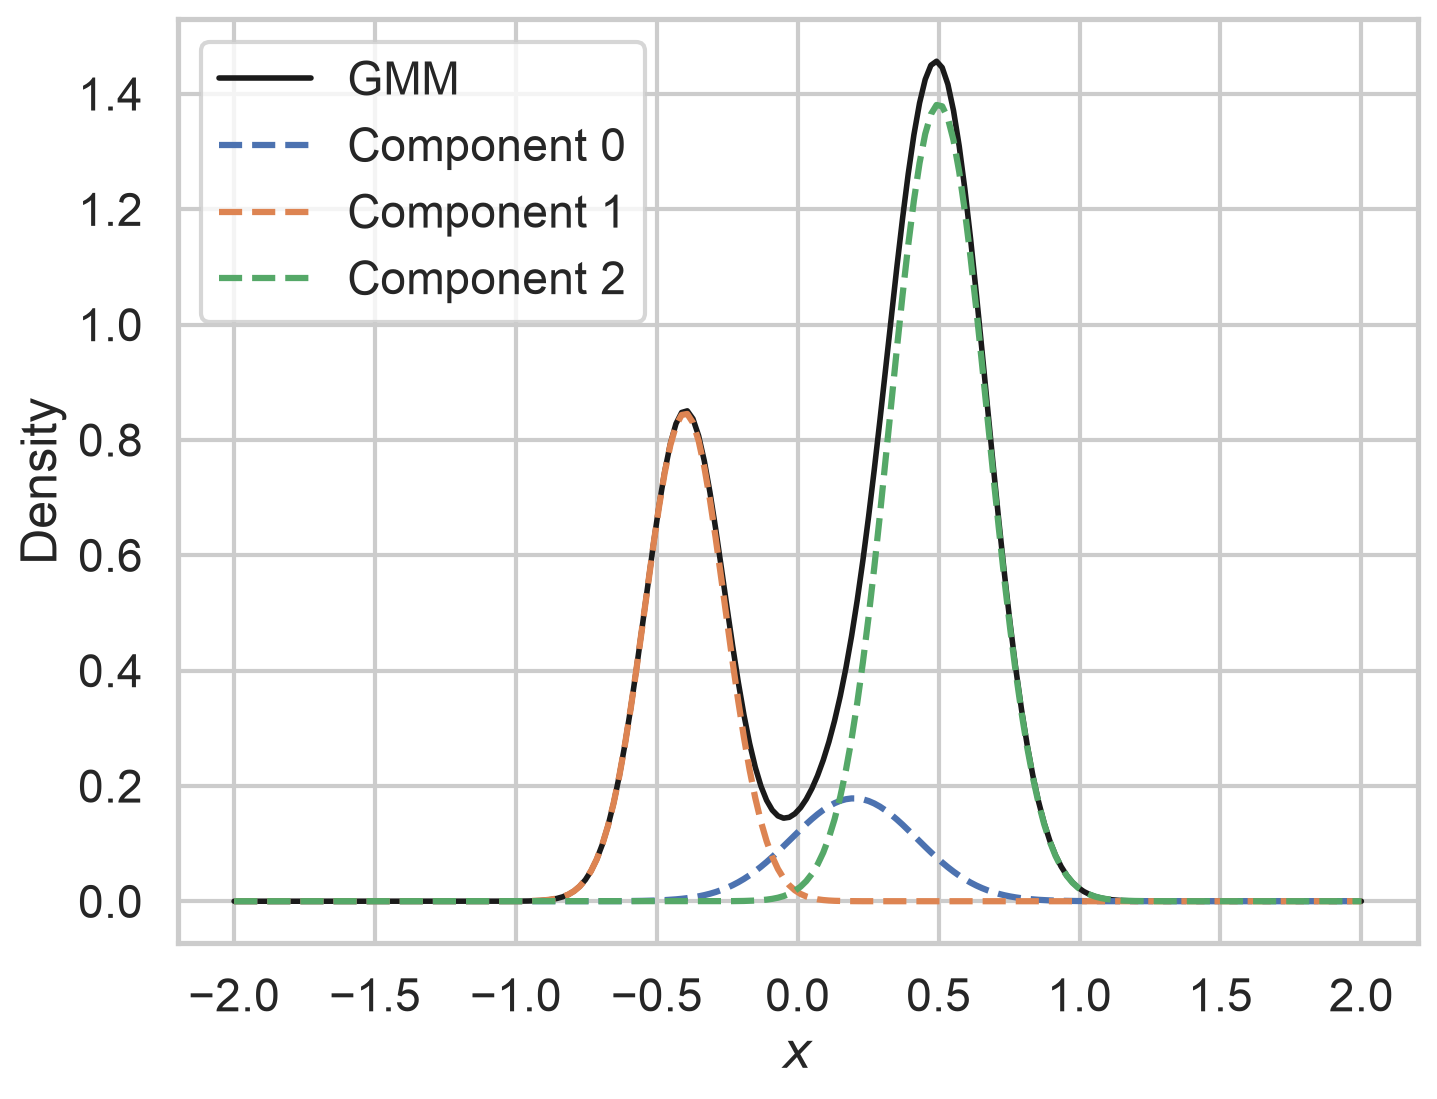

In [ ]:
xs = np.linspace(-2, 2, 200)
pdf_mix = gaussian_mixture_pdf(xs, weights, means, variances)
fig, ax = plt.subplots()
ax.plot(xs, pdf_mix, "k-", lw=2, label="GMM")
for i, (w, m, v) in enumerate(zip(weights, means, variances, strict=True)):
    pdf_comp = # TODO
    ax.plot(xs, pdf_comp, "--", label=f"Component {i}")
ax.set_xlabel("$x$")
ax.set_ylabel("Density")
ax.legend()
plt.show()

- To sample from a Gaussian mixture model, for each sample:

    - Pick a component $k \in \{1, \ldots, K\}$ with probability $\{\pi_1, \ldots, \pi_K\}$
    - Draw a sample from the selected Gaussian component $x_i \sim \mathcal{N}(\mu_k, \Sigma_k)$



In [ ]:
n_components = weights.shape[0]
n_samples = 10**4

rng = np.random.default_rng(SEED)
component_indices = rng.choice(# TODO, p=# TODO, size=# TODO)
gmm_samples = # TODO

In [13]:
component_indices[:40]

array([2, 1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 0, 2,
       2, 2, 0, 2, 2, 2, 0, 1, 2, 2, 2, 2, 1, 2, 1, 2, 0, 2])

In [14]:
weights

array([0.1, 0.3, 0.6])

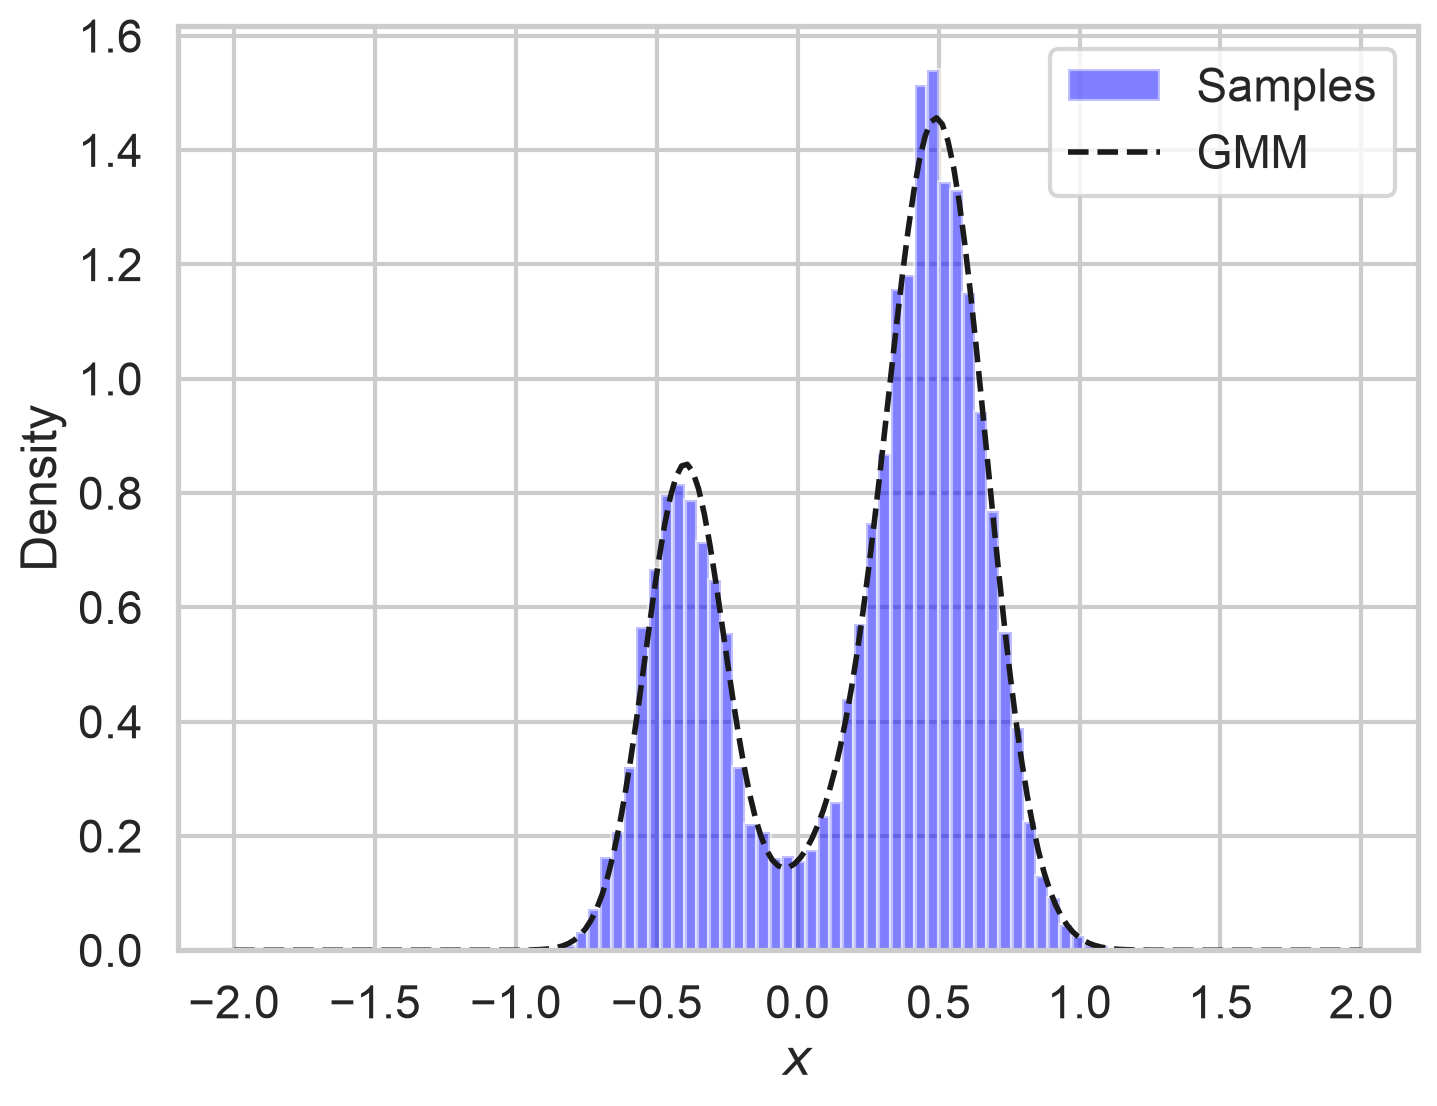

In [15]:
fig, ax = plt.subplots()
ax.hist(gmm_samples, bins=50, density=True, alpha=0.5, label="Samples", color="blue")
ax.plot(xs, pdf_mix, "k--", lw=2, label="GMM")
ax.set_xlabel("$x$")
ax.set_ylabel("Density")
ax.legend()
plt.show()

# Load data

[Old Faithful dataset](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/faithful.html)

- Description
    - Waiting time between eruptions and the duration of the eruption for the 
    Old Faithful geyser in Yellowstone National Park, Wyoming, USA.
- Format
    - A data frame with 272 observations on 2 variables.
        - eruptions: numeric, the eruption time (in minutes)
        - waiting: numeric, the waiting time to the next eruption (in minutes)

In [16]:
df = pd.read_csv("data/old_faithful.csv", index_col=0)

In [17]:
df.shape

(272, 2)

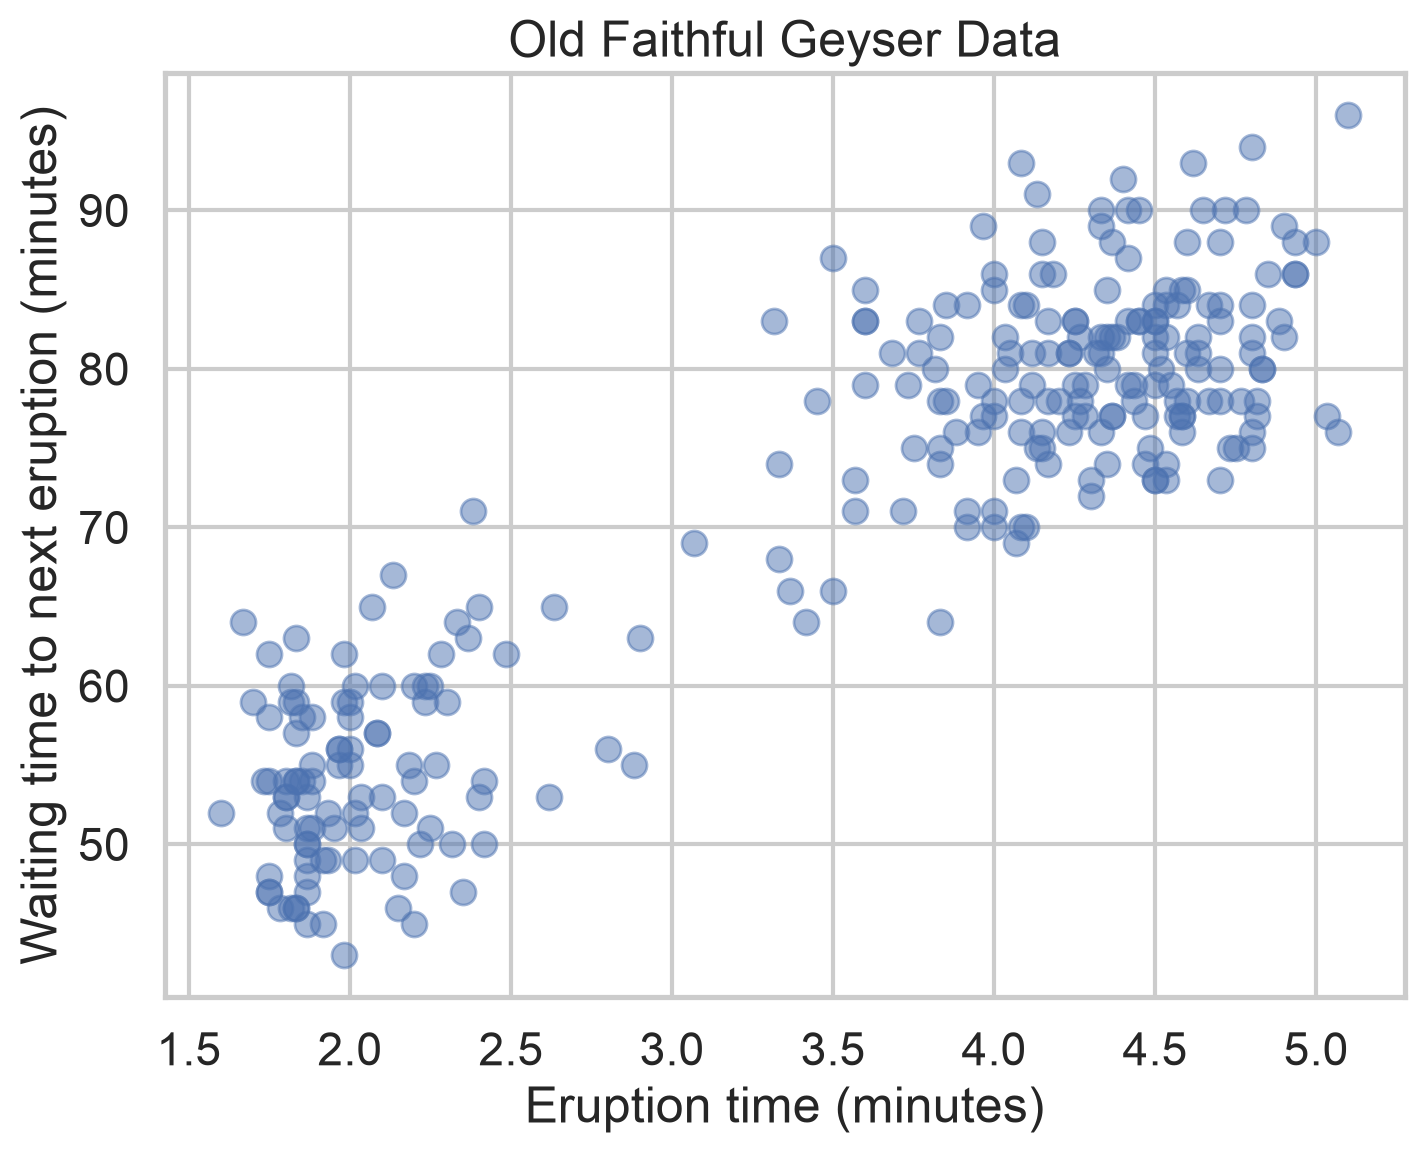

In [18]:
fig, ax = plt.subplots()
ax.plot(df["eruptions"], df["waiting"], "o", alpha=0.5)
ax.set_xlabel("Eruption time (minutes)")
ax.set_ylabel("Waiting time to next eruption (minutes)")
ax.set_title("Old Faithful Geyser Data")
plt.show()

In [19]:
data = df.to_numpy()

In [20]:
mean_estim, cov_estim = multivariate_normal.fit(data)

Contour plot

In [21]:
x = np.linspace(data[:, 0].min(), data[:, 0].max(), 200)
y = np.linspace(data[:, 1].min(), data[:, 1].max(), 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))
Z = multivariate_normal.pdf(pos, mean=mean_estim, cov=cov_estim)

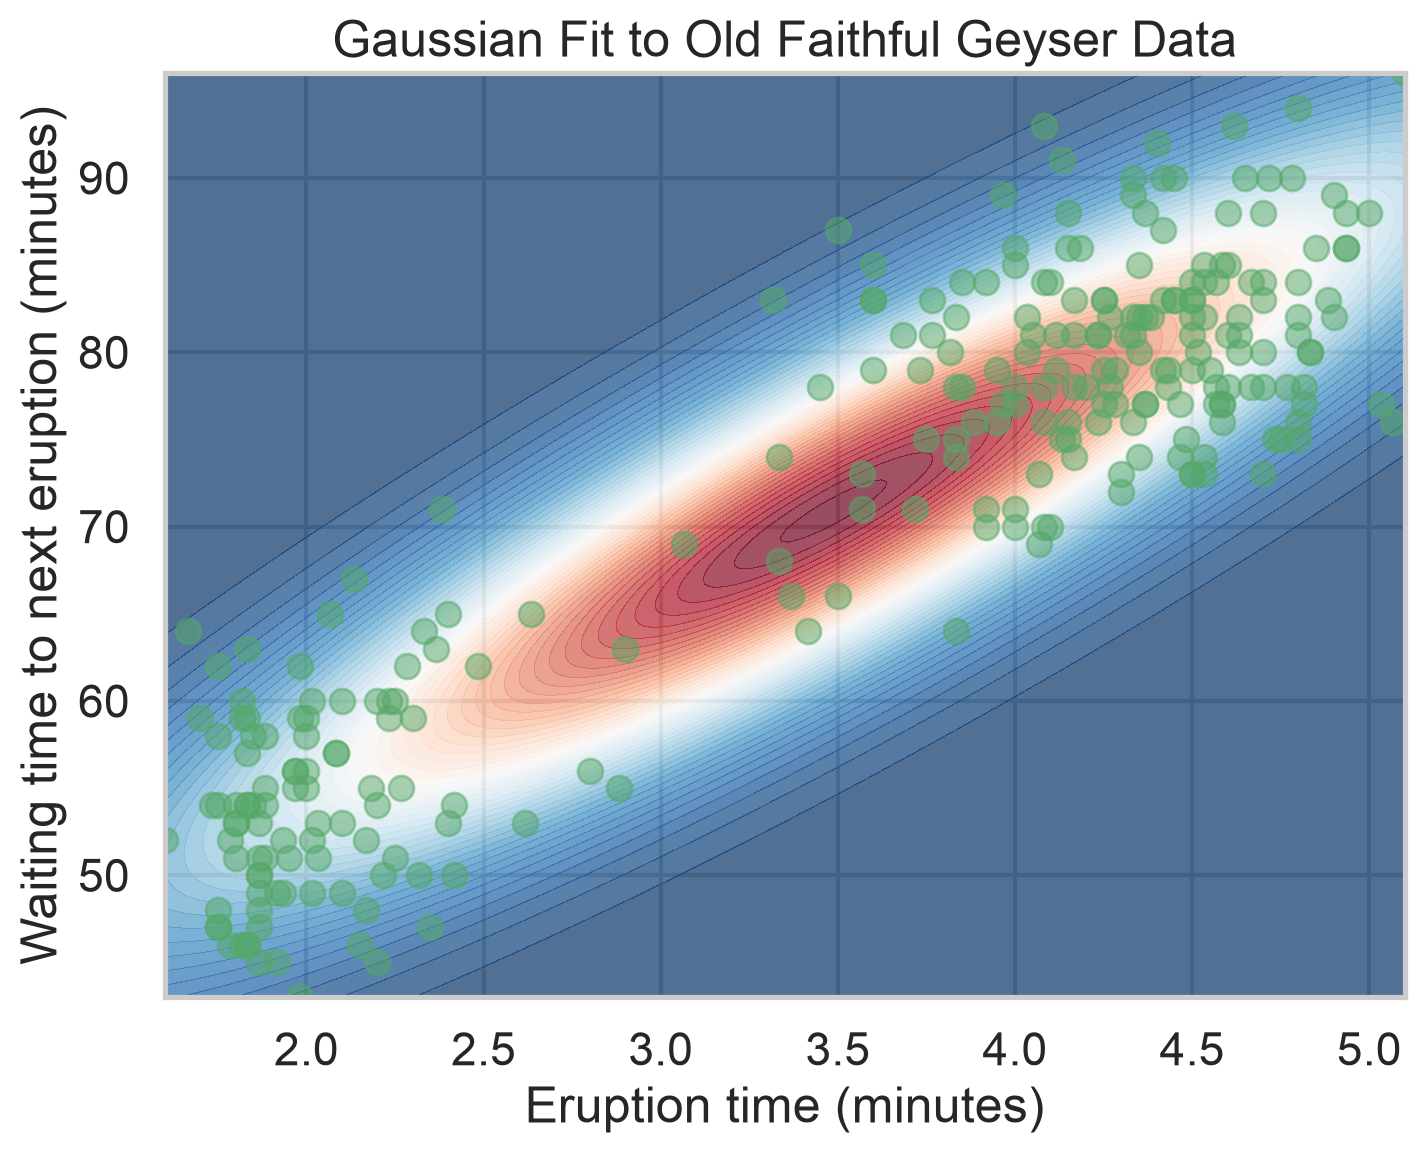

In [22]:
fig, ax = plt.subplots()
ax.contourf(X, Y, Z, levels=50, cmap="RdBu_r", alpha=0.7)
ax.plot(data[:, 0], data[:, 1], "go", alpha=0.5)
ax.set_xlabel("Eruption time (minutes)")
ax.set_ylabel("Waiting time to next eruption (minutes)")
ax.set_title("Gaussian Fit to Old Faithful Geyser Data")
plt.show()

Another contour plot

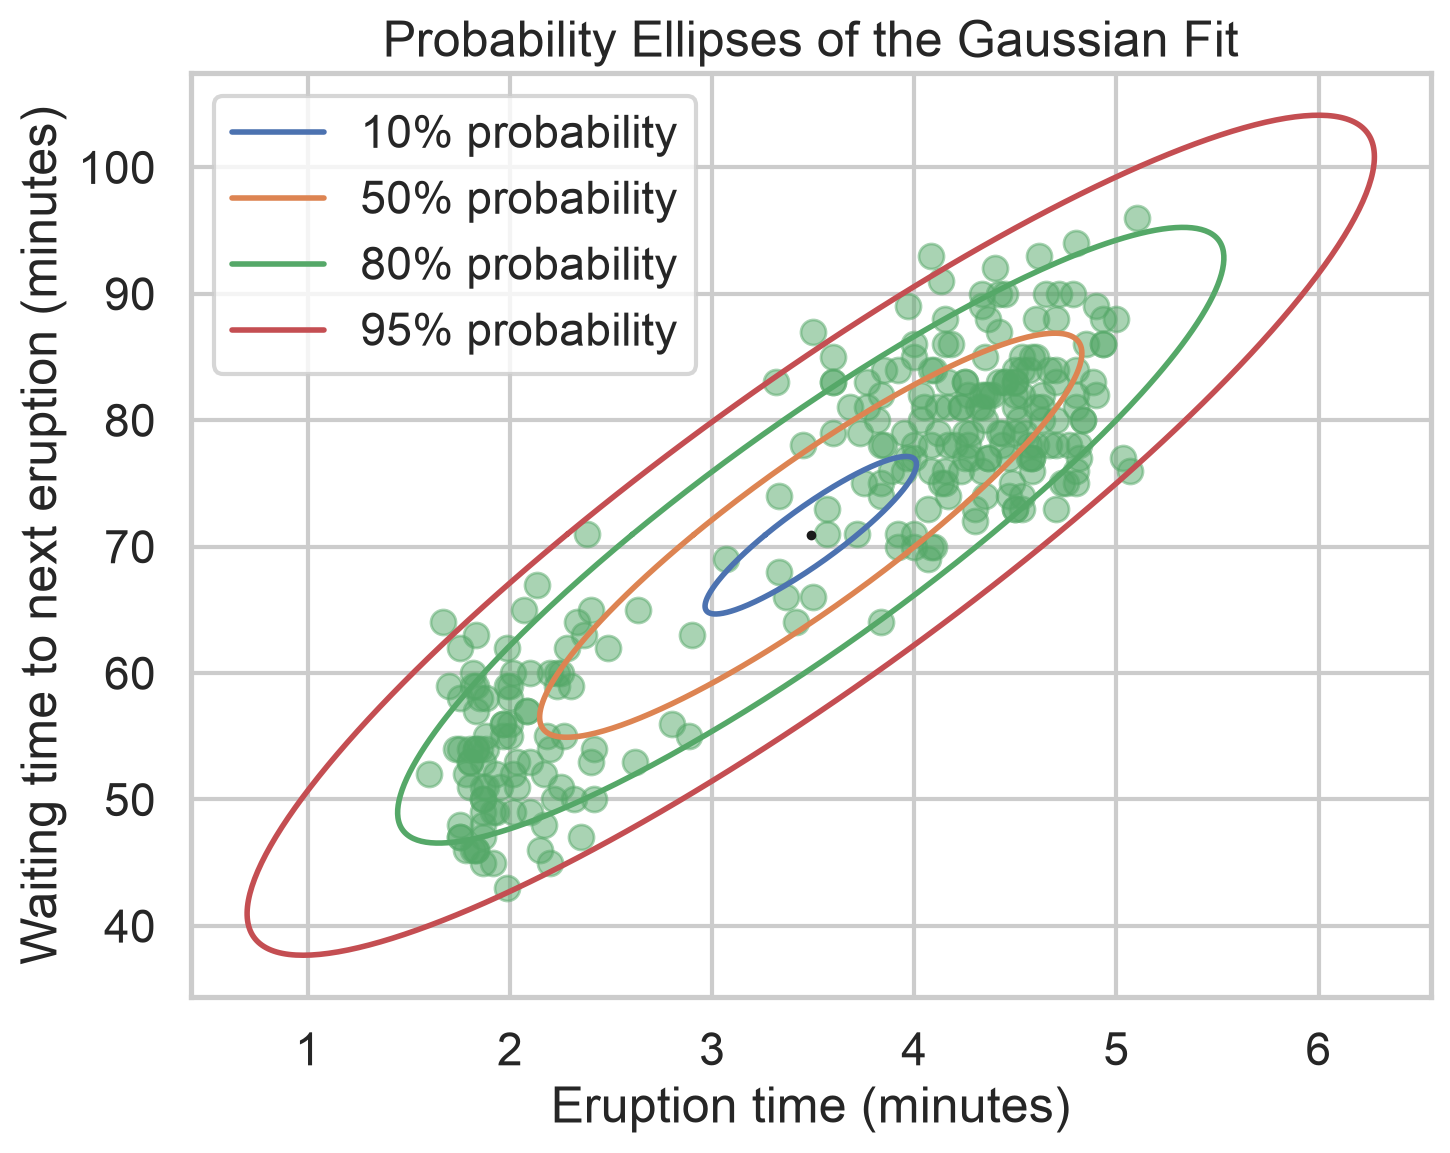

In [23]:
# ellipse "radii" for chosen enclosed probabilities
probs = [0.1, 0.50, 0.80, 0.95]
cs = chi2.ppf(probs, df=2)  # c-values for the Mahalanobis distance^2

# eigen-decomposition
lam, V = np.linalg.eigh(cov_estim)  # lam: eigenvalues (>=0), V: eigenvectors (columns)
L = V @ np.diag(np.sqrt(lam))  # linear map turning unit circle -> 1-sigma ellipse

# parametric unit circle
theta = np.linspace(0, 2 * np.pi, 400)
unit = np.vstack((np.cos(theta), np.sin(theta)))  # shape (2, 400)

fig, ax = plt.subplots()
ax.plot(data[:, 0], data[:, 1], "go", alpha=0.5)
for p, c in zip(probs, cs, strict=True):
    # scale by sqrt(c) to get the desired ellipse
    ellipse = mean_estim.reshape(2, 1) + np.sqrt(c) * (L @ unit)
    ax.plot(ellipse[0], ellipse[1], lw=2, label=f"{int(100 * p)}% probability")

ax.plot(mean_estim[0], mean_estim[1], ".k", ms=5)  # plot mean
ax.set_xlabel("Eruption time (minutes)")
ax.set_ylabel("Waiting time to next eruption (minutes)")
ax.set_title("Probability Ellipses of the Gaussian Fit")
ax.legend()
plt.show()

## Expectation-Maximization (EM) algorithm for GMMs

- Step 1: Initialize the parameters (means, covariances, and mixture weights) of the Gaussian components and compute the initial log-likelihood.
- Step 2: E-step: Compute the responsibilities (posterior probabilities) for each data point belonging to each Gaussian component.
- Step 3: M-step: Update the parameters of the Gaussian components using the responsibilities computed in the E-step.
- Step 4: Compute the log-likelihood of the data given the current parameters.
- Step 5: Check for convergence (e.g., if the change in log-likelihood is below a certain threshold). If not converged, return to Step 2.

The log-likelihood $\sum_i \log \sum_k \pi_k \mathcal{N}(x_i \mid \mu_k, \Sigma_k)$ is computed
in log-space with `logsumexp` to avoid underflow when the densities are tiny.

In [24]:
# Step 1: initialize parameters and compute the initial log-likelihood

em_means = np.array([[1.5, 70], [4, 80]])
em_covariances = np.array([[[0.2, 2], [2, 40]], [[0.5, 4], [4, 40]]])
em_weights = np.array([0.5, 0.5])

x_data = df.to_numpy()


def log_weighted_pdfs(x, weights, means, covariances):
    """Return log(pi_k) + log N(x_i | mu_k, Sigma_k), shape (n_components, n_samples)."""
    return np.array(
        [
            np.log(w) + multivariate_normal.logpdf(x, mean=m, cov=c)
            for w, m, c in zip(weights, means, covariances, strict=True)
        ]
    )


log_wpdfs = log_weighted_pdfs(x_data, em_weights, em_means, em_covariances)
loglik = logsumexp(log_wpdfs, axis=0).sum()
print(f"Initial log-likelihood: {loglik:.4f}")

Initial log-likelihood: -2392.4690


In [25]:
resp = np.exp(log_wpdfs - logsumexp(log_wpdfs, axis=0))  # responsibilities
resp.shape, np.allclose(resp.sum(axis=0), 1)

((2, 272), True)

In [ ]:
TOL = 1e-8
MAX_STEPS = 100

for step in range(1, MAX_STEPS + 1):
    # Step 2: E-step - compute responsibilities, shape (n_components, n_samples)
    resp = np.exp(log_wpdfs - logsumexp(log_wpdfs, axis=0))

    # Step 3: M-step - update parameters
    N_k = resp.sum(axis=1)  # shape (n_components,)
    em_weights = # TODO
    em_means = # TODO
    em_covariances = np.array(
        [
            (resp[k][:, None] * (x_data - em_means[k])).T
            @ (x_data - em_means[k])
            / N_k[k]
            for k in range(len(em_weights))
        ]
    )

    # Step 4: compute the log-likelihood
    log_wpdfs = log_weighted_pdfs(x_data, em_weights, em_means, em_covariances)
    loglik_new = logsumexp(log_wpdfs, axis=0).sum()
    print(f"Step {step}: log-likelihood is {loglik_new:.4f}")

    # Step 5: check for convergence
    if np.abs(loglik_new - loglik) < TOL:
        print("Converged!")
        break
    loglik = loglik_new

Step 1: log-likelihood is -1222.6874
Step 2: log-likelihood is -1192.9896
Step 3: log-likelihood is -1173.9098
Step 4: log-likelihood is -1155.6841
Step 5: log-likelihood is -1142.0770
Step 6: log-likelihood is -1135.3432
Step 7: log-likelihood is -1131.8721
Step 8: log-likelihood is -1130.5107
Step 9: log-likelihood is -1130.2869
Step 10: log-likelihood is -1130.2655
Step 11: log-likelihood is -1130.2641
Step 12: log-likelihood is -1130.2640
Step 13: log-likelihood is -1130.2640
Step 14: log-likelihood is -1130.2640
Step 15: log-likelihood is -1130.2640
Step 16: log-likelihood is -1130.2640
Converged!


In [27]:
print("Optimal parameters:\n")
print("weights:", em_weights, "\n")
print("means:", em_means, "\n")
print("covariances:", em_covariances)

Optimal parameters:

weights: [0.35587282 0.64412718] 

means: [[ 2.03638835 54.47851535]
 [ 4.28966188 79.96811409]] 

covariances: [[[ 0.06916759  0.43516678]
  [ 0.43516678 33.69727633]]

 [[ 0.16996855  0.94061077]
  [ 0.94061077 36.04622768]]]


In [28]:
x = np.linspace(data[:, 0].min(), data[:, 0].max(), 200)
y = np.linspace(data[:, 1].min(), data[:, 1].max(), 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))
Z = sum(
    w * multivariate_normal.pdf(pos, mean=m, cov=c)
    for w, m, c in zip(em_weights, em_means, em_covariances, strict=True)
)

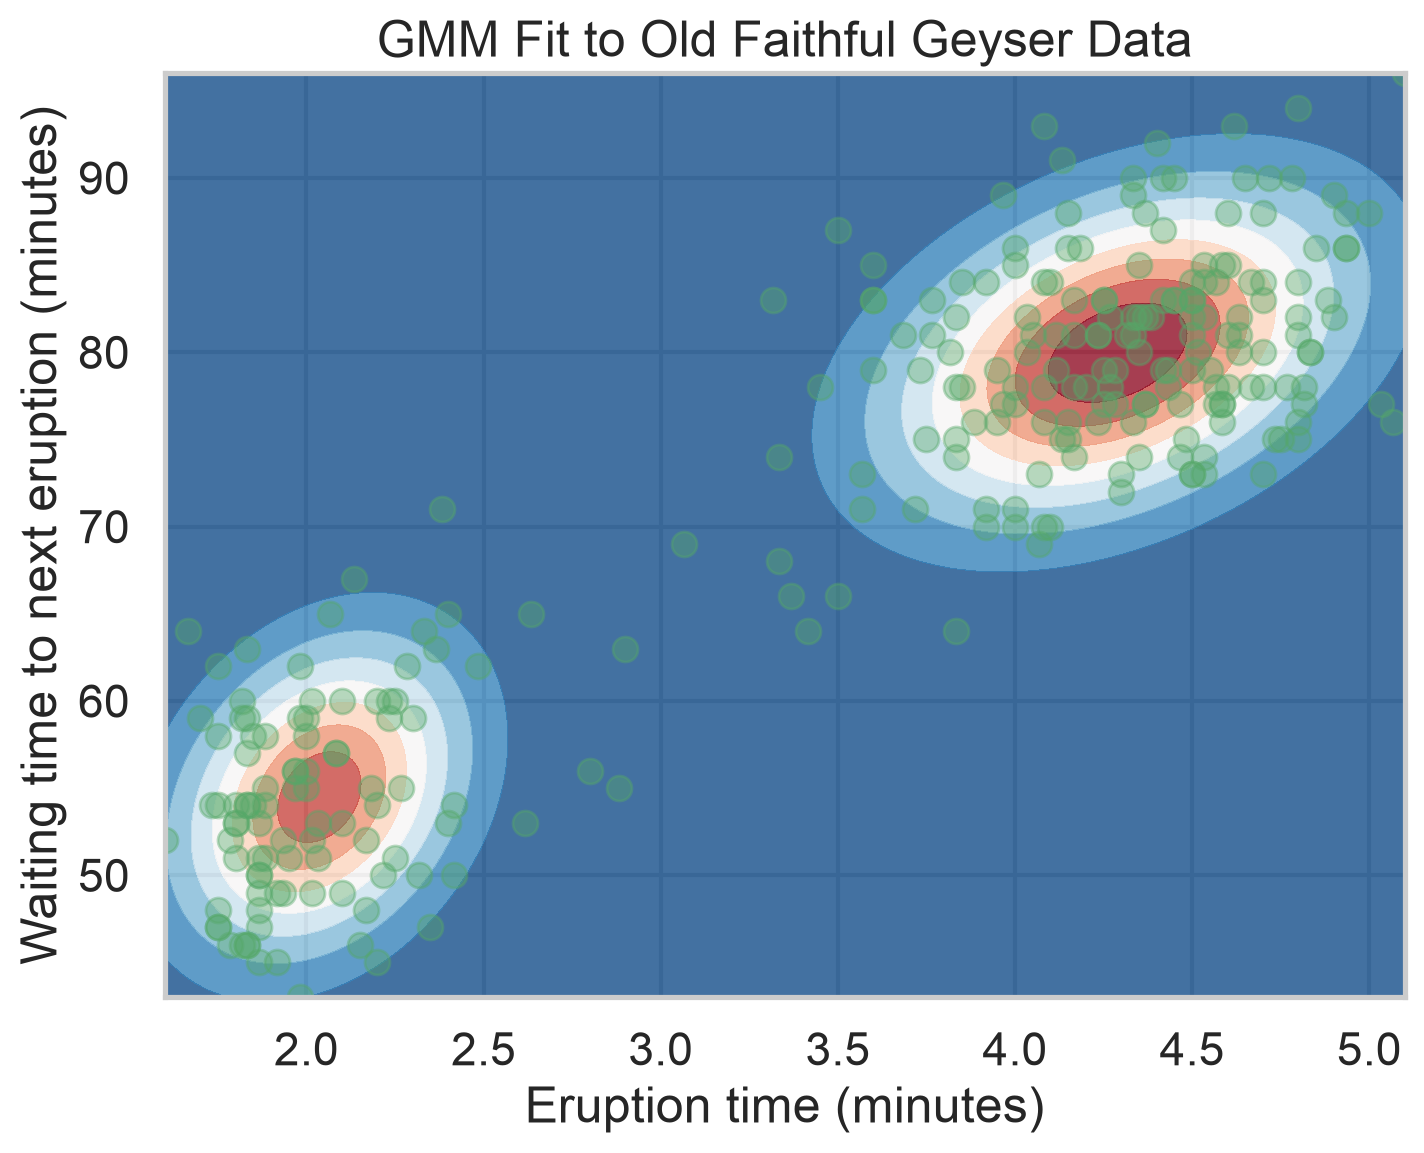

In [29]:
fig, ax = plt.subplots()
ax.plot(x_data[:, 0], x_data[:, 1], "go", alpha=0.4)
ax.contourf(X, Y, Z, levels=10, cmap="RdBu_r", alpha=0.8)
ax.set_xlabel("Eruption time (minutes)")
ax.set_ylabel("Waiting time to next eruption (minutes)")
ax.set_title("GMM Fit to Old Faithful Geyser Data")
plt.show()

We can compare our results to the [GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html) implementation from `sklearn`.

In [ ]:
from sklearn.mixture import GaussianMixture

gm = # TODO
gm.means_, gm.covariances_, gm.weights_

(array([[ 2.03638856, 54.47851745],
        [ 4.28966207, 79.96811632]]),
 array([[[ 0.06916776,  0.43516851],
         [ 0.43516851, 33.69728811]],
 
        [[ 0.16996832,  0.94060779],
         [ 0.94060779, 36.04619413]]]),
 array([0.3558729, 0.6441271]))

In [31]:
gm.means_

array([[ 2.03638856, 54.47851745],
       [ 4.28966207, 79.96811632]])

In [32]:
em_means

array([[ 2.03638835, 54.47851535],
       [ 4.28966188, 79.96811409]])

In [33]:
gm.covariances_

array([[[ 0.06916776,  0.43516851],
        [ 0.43516851, 33.69728811]],

       [[ 0.16996832,  0.94060779],
        [ 0.94060779, 36.04619413]]])

In [34]:
em_covariances

array([[[ 0.06916759,  0.43516678],
        [ 0.43516678, 33.69727633]],

       [[ 0.16996855,  0.94061077],
        [ 0.94061077, 36.04622768]]])

In [35]:
em_weights

array([0.35587282, 0.64412718])

In [36]:
gm.weights_

array([0.3558729, 0.6441271])